<a href="https://colab.research.google.com/github/239-blip/mssp607/blob/main/Assignments/assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
#prepare data
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

!git clone https://github.com/239-blip/mssp607
%cd mssp607
df=pd.read_csv("data/InternetSales.csv", encoding="cp1252",low_memory=False)


df["OrderDate"] = pd.to_datetime(df["OrderDate"], format="%m/%d/%Y")
df["Year"] = df["OrderDate"].dt.year

df["ProductCategory"] = "Accessories"

bikes = df["EnglishProductName"].str.startswith(
    ("Mountain-", "Road-", "Touring-"), na=False
)

clothing = df["EnglishProductName"].str.contains(
    "Jersey|Shorts|Gloves|Vest|Socks|Cap",
    case=False, na=False
)

df.loc[bikes, "ProductCategory"] = "Bikes"
df.loc[clothing, "ProductCategory"] = "Clothing"

Cloning into 'mssp607'...
remote: Enumerating objects: 202, done.
remote: Counting objects: 100% (202/202), done.
remote: Compressing objects: 100% (187/187), done.
remote: Total 202 (delta 88), reused 15 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (202/202), 7.46 MiB | 7.21 MiB/s, done.
Resolving deltas: 100% (88/88), done.
/content/mssp607/mssp607


EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


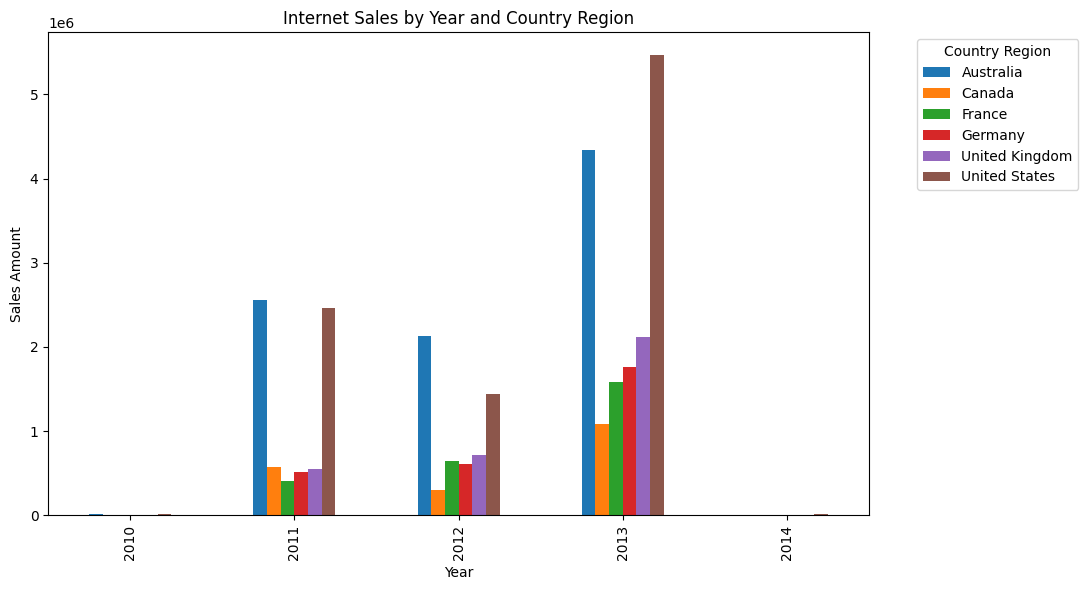

In [12]:
#Question 1
sales_by_year_country = df.pivot_table(
    index="Year",
    columns="EnglishCountryRegionName",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

display(sales_by_year_country.round(2))

sales_by_year_country.plot(kind="bar", figsize=(11, 6))

plt.title("Internet Sales by Year and Country Region")
plt.xlabel("Year")
plt.ylabel("Sales Amount")
plt.legend(title="Country Region",
           bbox_to_anchor=(1.05, 1),
           loc="upper left")
plt.tight_layout()
plt.show()

In [13]:
#Question 2
customers = df.drop_duplicates(subset="CustomerKey")

income_stats = customers.groupby(
    ["EnglishCountryRegionName", "Gender"]
)["YearlyIncome"].agg(["count", "min", "max", "mean", "std"]).round(2)

display(income_stats)

gender_counts = pd.crosstab(
    customers["EnglishCountryRegionName"],
    customers["Gender"]
)

display(gender_counts)

count    min     max      mean       std
EnglishCountryRegionName Gender                                          
Australia                F        1777  10000  160000  65284.19  31164.36
                         M        1814  10000  170000  63412.35  32450.71
Canada                   F         767  10000  170000  56505.87  19181.55
                         M         804  10000  170000  57798.51  21214.77
France                   F         893  10000  110000  35341.55  26915.85
                         M         917  10000  110000  36172.30  27633.45
Germany                  F         874  10000  130000  43810.07  35715.76
                         M         906  10000  130000  42108.17  35277.49
United Kingdom           F         934  10000  170000  52184.15  48288.44
                         M         979  10000  170000  52155.26  48593.22
United States            F        3888  10000  170000  63276.75  25166.56
                         M        3931  10000  170000  63953.19  26228.43

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


,TotalSales,AverageUnitPrice,UnitsSold,SalesSharePct
ProductCategory,,,,
Bikes,28318144.65,1862.42,15205,96.46
Accessories,700759.96,19.42,36092,2.39
Clothing,339772.61,37.33,9101,1.16


Highest-sales category: Bikes
Average unit price: $1,862.42


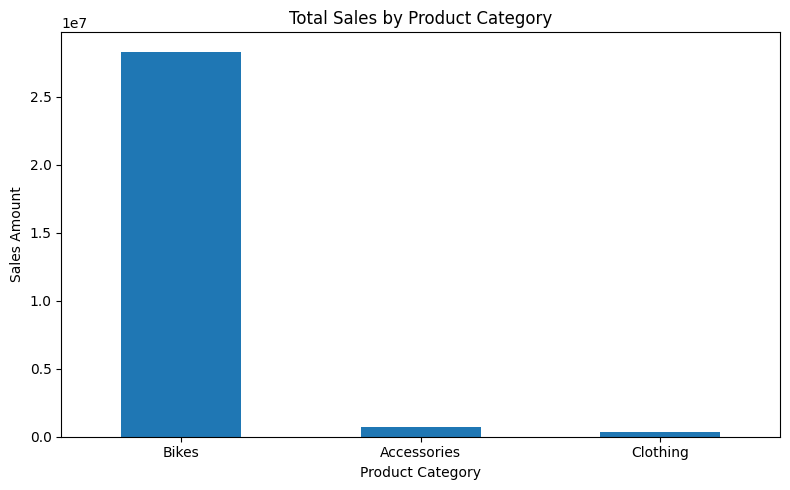

In [14]:
#Question3
category_stats = df.groupby("ProductCategory").agg(
    TotalSales=("SalesAmount", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    UnitsSold=("OrderQuantity", "sum")
).sort_values("TotalSales", ascending=False)

category_stats["SalesSharePct"] = (
    category_stats["TotalSales"] /
    category_stats["TotalSales"].sum() * 100
)

display(category_stats.round(2))

top_category = category_stats.index[0]

print("Highest-sales category:", top_category)
print(f"Average unit price: ${category_stats.loc[top_category, 'AverageUnitPrice']:,.2f}")

category_stats["TotalSales"].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,TotalSales,Customers,Orders,SalesPerCustomer,SalesPerOrder,AverageYearlyIncome
HouseOwnerFlag,,,,,,
Non-homeowners,8973327.42,5982,8601,1500.05,1043.29,55172.18
Homeowners,20385349.80,12502,19058,1630.57,1069.65,58326.67


Difference in sales per customer: 8.70%


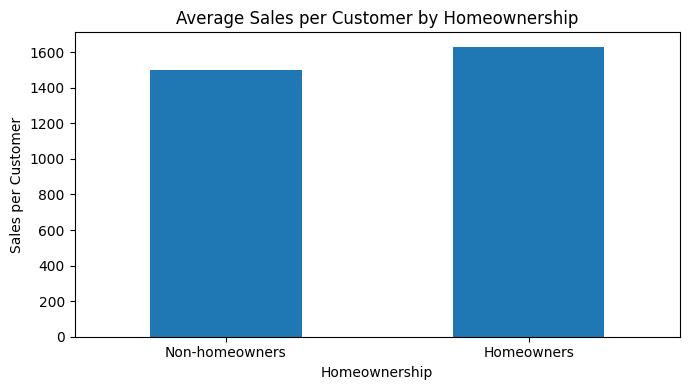

In [15]:
#Question4
home_stats = df.groupby("HouseOwnerFlag").agg(
    TotalSales=("SalesAmount", "sum"),
    Customers=("CustomerKey", "nunique"),
    Orders=("SalesOrderNumber", "nunique")
)

home_stats["SalesPerCustomer"] = (
    home_stats["TotalSales"] / home_stats["Customers"]
)

home_stats["SalesPerOrder"] = (
    home_stats["TotalSales"] / home_stats["Orders"]
)

home_stats["AverageYearlyIncome"] = customers.groupby(
    "HouseOwnerFlag"
)["YearlyIncome"].mean()

home_stats = home_stats.rename(
    index={0: "Non-homeowners", 1: "Homeowners"}
)

display(home_stats.round(2))

difference_pct = (
    home_stats.loc["Homeowners", "SalesPerCustomer"] /
    home_stats.loc["Non-homeowners", "SalesPerCustomer"] - 1
) * 100

print(f"Difference in sales per customer: {difference_pct:.2f}%")

home_stats["SalesPerCustomer"].plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Average Sales per Customer by Homeownership")
plt.xlabel("Homeownership")
plt.ylabel("Sales per Customer")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
home_by_country = df.groupby(
    ["EnglishCountryRegionName", "HouseOwnerFlag"]
).agg(
    TotalSales=("SalesAmount", "sum"),
    Customers=("CustomerKey", "nunique")
)

home_by_country["SalesPerCustomer"] = (
    home_by_country["TotalSales"] /
    home_by_country["Customers"]
)

display(home_by_country.round(2))

TotalSales  Customers  \
EnglishCountryRegionName HouseOwnerFlag                          
Australia                0               3255882.67       1302   
                         1               5805117.92       2289   
Canada                   0                588109.59        515   
                         1               1389735.27       1056   
France                   0                645802.51        634   
                         1               1998215.20       1176   
Germany                  0                765781.73        602   
                         1               2128530.60       1178   
United Kingdom           0                944337.17        644   
                         1               2447375.04       1269   
United States            0               2773413.75       2285   
                         1               6616375.76       5534   

                                         SalesPerCustomer  
EnglishCountryRegionName HouseOwnerFlag                    
Australia                0                        2500.68  
                         1                        2536.09  
Canada                   0                        1141.96  
                         1                        1316.04  
France                   0                        1018.62  
                         1                        1699.16  
Germany                  0                        1272.06  
                         1                        1806.90  
United Kingdom           0                        1466.36  
                         1                        1928.59  
United States            0                        1213.75  
                         1                        1195.59

ProductCategory,Accessories,Bikes,Clothing
Year,,,
2010,0.00,43421.04,0.00
2011,0.00,7075525.93,0.00
2012,2147.08,5839695.33,642.79
2013,668241.53,15359502.36,323806.45
2014,30371.35,0.00,15323.37


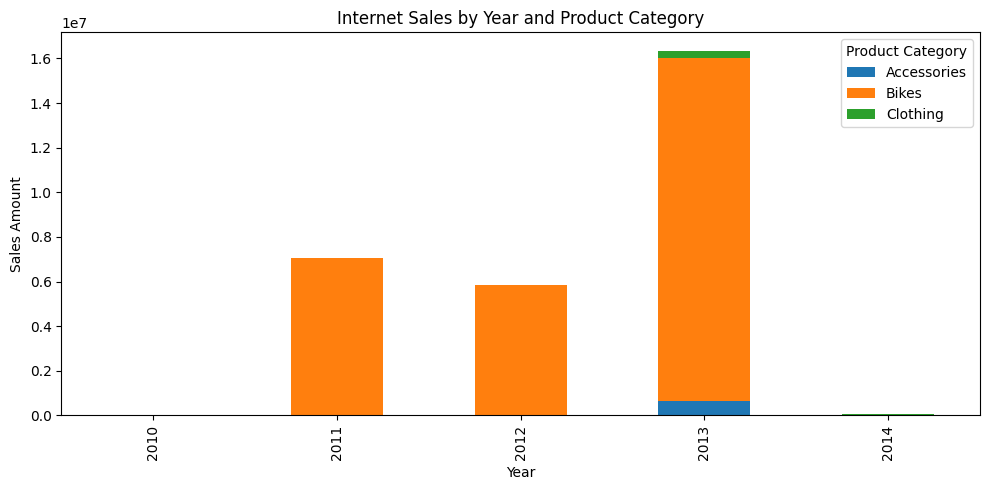

In [17]:
#Sales by Year and Product Category
sales_by_year_category = df.pivot_table(
    index="Year",
    columns="ProductCategory",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

display(sales_by_year_category.round(2))

sales_by_year_category.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Internet Sales by Year and Product Category")
plt.xlabel("Year")
plt.ylabel("Sales Amount")
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

In [18]:
sales_by_country_category = df.pivot_table(

    index="EnglishCountryRegionName",

    columns="ProductCategory",

    values="SalesAmount",

    aggfunc="sum",

    fill_value=0

)

display(sales_by_country_category.round(2))

ProductCategory,Accessories,Bikes,Clothing
EnglishCountryRegionName,,,
Australia,138690.63,8852050.00,70259.95
Canada,103377.85,1821302.39,53164.62
France,63406.78,2553575.71,27035.22
Germany,62232.59,2808514.35,23565.40
United Kingdom,76630.04,3282842.66,32239.51
United States,256422.07,8999859.53,133507.91


In [19]:
top_products = df.groupby(
    "EnglishProductName"
)["SalesAmount"].sum().sort_values(
    ascending=False
).head(10)

display(top_products.round(2))

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1373469.55
"Mountain-200 Black, 42",1363142.09
"Mountain-200 Silver, 38",1339462.79
"Mountain-200 Silver, 46",1301100.10
"Mountain-200 Black, 38",1294866.14
"Mountain-200 Silver, 42",1257434.57
"Road-150 Red, 48",1205876.99
"Road-150 Red, 62",1202298.72
"Road-150 Red, 52",1080637.54


In [20]:
df["GrossProfit"] = (
    df["SalesAmount"] - df["TotalProductCost"]
)

category_profit = df.groupby(
    "ProductCategory"
)[["SalesAmount", "GrossProfit"]].sum()

category_profit["GrossMarginPct"] = (
    category_profit["GrossProfit"] /
    category_profit["SalesAmount"] * 100
)

display(category_profit.round(2))

,SalesAmount,GrossProfit,GrossMarginPct
ProductCategory,,,
Accessories,700759.96,438674.57,62.60
Bikes,28318144.65,11505796.50,40.63
Clothing,339772.61,136412.58,40.15
